[saved] results\figures\fig_perturbation_contrast.png
[saved] results\figures\fig_perturbation_contrast.pdf


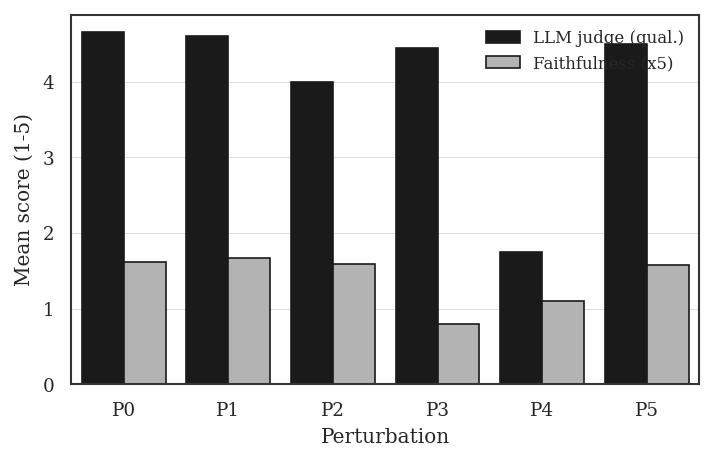

[saved] results\figures\fig_dose_response.png
[saved] results\figures\fig_dose_response.pdf


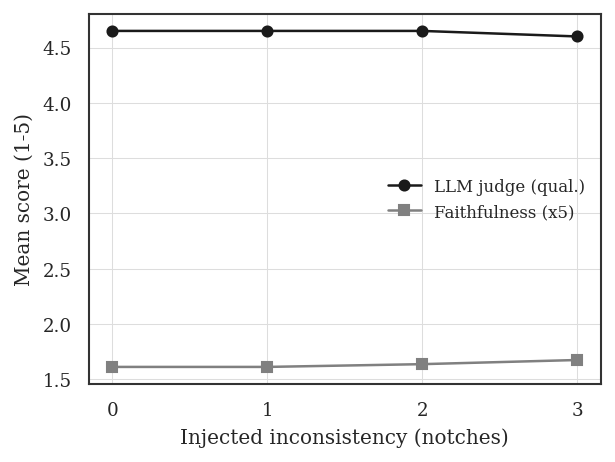

[saved] results\figures\fig_ablation_2x2.png
[saved] results\figures\fig_ablation_2x2.pdf


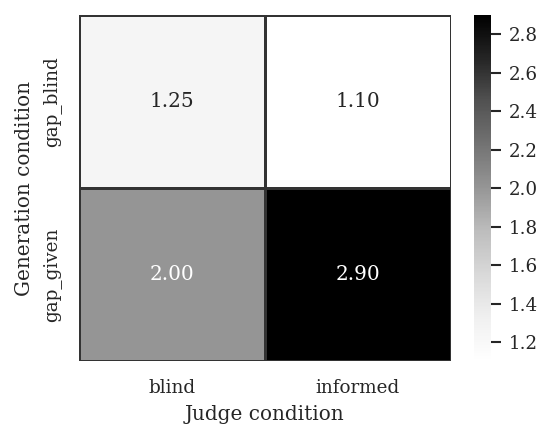

All figures written to results/figures/


In [2]:
# ============================================================================
# 05_figures_tables.ipynb  —  Final publication figures and tables
# ----------------------------------------------------------------------------
# Single-cell notebook. All code and comments are in English.
# Figures: seaborn grayscale, no captions, dpi=600, saved as both PNG and PDF.
# Run order: 00 -> 01 -> 02 -> 03 -> 04 -> 05.
# ============================================================================
import sys, os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd

# Make src/ importable regardless of the notebook's working directory.
_HERE = Path.cwd()
_ROOT = _HERE if (_HERE / "src").exists() else _HERE.parent
sys.path.insert(0, str(_ROOT / "src"))
from common import (PROJECT_ROOT, DATA_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR,
                    load_env, set_grayscale_style, save_fig, save_table,
                    require_input, RANDOM_SEED)

import matplotlib.pyplot as plt
import seaborn as sns
set_grayscale_style()
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore")
# NOTE: absolute local paths are never printed (anonymity for double-blind review).

# ----------------------------------------------------------------------------
# PURPOSE
#   Assemble the manuscript's figures and tables from the saved intermediates.
#   All figures: seaborn grayscale, NO captions, dpi=600, PNG + PDF.
#
# INPUT   data/scored.parquet, results/tables/tab_divergence.csv,
#         results/tables/tab_ablation_2x2.csv
# OUTPUT  results/figures/fig_perturbation_contrast.{png,pdf}
#         results/figures/fig_dose_response.{png,pdf}
#         results/figures/fig_ablation_2x2.{png,pdf}
# ----------------------------------------------------------------------------
s = pd.read_parquet(require_input(DATA_DIR / "scored.parquet",
                                  hint="Run 03_judge_metric first."))
head = s[(s.judge_cond=="informed") & (s.condition=="gap_given")].copy()
head["faith5"] = head["faithfulness"] * 5.0

# --- Figure 1: per-perturbation contrast (judge qual vs faithfulness x5) ---
order = ["P0","P1","P2","P3","P4","P5"]
agg = (head[head.k.isin([0,3])]
       .groupby("pert")[["judge_qual","faith5"]].mean()
       .reindex(order).reset_index())
long = agg.melt(id_vars="pert", value_vars=["judge_qual","faith5"],
                var_name="channel", value_name="score")
long["channel"] = long["channel"].map({"judge_qual":"LLM judge (qual.)",
                                        "faith5":"Faithfulness (x5)"})
fig, ax = plt.subplots(figsize=(5.4, 3.2))
sns.barplot(data=long, x="pert", y="score", hue="channel",
            palette=["#1a1a1a","#b3b3b3"], edgecolor="#1a1a1a", ax=ax)
ax.set_xlabel("Perturbation"); ax.set_ylabel("Mean score (1-5)")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_perturbation_contrast"); plt.show()

# --- Figure 2: P1 dose-response ---
dose = (head[head.pert.isin(["P0","P1"])]
        .assign(notch=lambda d: np.where(d.pert=="P0", 0, d.k))
        .groupby("notch")[["judge_qual","faith5"]].mean().reset_index())
fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.plot(dose.notch, dose.judge_qual, marker="o", color="#1a1a1a", label="LLM judge (qual.)")
ax.plot(dose.notch, dose.faith5, marker="s", color="#808080", label="Faithfulness (x5)")
ax.set_xlabel("Injected inconsistency (notches)"); ax.set_ylabel("Mean score (1-5)")
ax.set_xticks([0,1,2,3]); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_dose_response"); plt.show()

# --- Figure 3: 2x2 ablation heatmap (P4 drop) ---
abl = pd.read_csv(require_input(TABLES_DIR / "tab_ablation_2x2.csv",
                                hint="Run 04_ablation first."))
mat = abl.pivot(index="generation", columns="judge", values="P4_drop")
fig, ax = plt.subplots(figsize=(4.0, 3.0))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="Greys", cbar=True,
            linewidths=0.5, linecolor="#333333", ax=ax)
ax.set_xlabel("Judge condition"); ax.set_ylabel("Generation condition")
save_fig(fig, "fig_ablation_2x2"); plt.show()

print("All figures written to results/figures/")
